# Related Papers:
- https://aclanthology.org/2024.acl-short.2.pdf
- https://aclanthology.org/2024.emnlp-main.171.pdf
- https://arxiv.org/pdf/2408.09174v1
- https://aclanthology.org/2025.findings-emnlp.638.pdf
- https://aclanthology.org/2025.emnlp-main.363.pdf

In [61]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv
from knowledge_maze.tools.utils import load_json

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Data Creation:

## 1. Harvest Wikipedia pages with tables:

1. **The Discovery Phase (The Wide Net)**
   - Input: 22 Subject Groups (e.g., Infrastructure, Sports).
   - Action: We hit the Wikipedia API with two distinct patterns:
     - Prefix Mining: Grabbing every page starting with "Entity in/of..."
     - Search Mining: Finding every page with "List of [Entity]" in the title.
     - Goal: Maximum recall. We want to find everything that might be a list.
2. **The Validation Phase (The Filter)**
   - Action: We open every page found in Phase 1 (asynchronously for speed).
   - Logic: We look for the "DNA" of a table: the {| or wikitable tags.
   - Outcome: We discard the "stub" articles or prose-only pages that don't actually contain structured data.
3. **The Clustering Phase (The De-duplicator)**
   - Problem: Wikipedia often has "List of 2023 Films" and "List of films of 2023." These are duplicates.
   - Action: Using TF-IDF to cluster similar page titles.
   - If two titles are >80% similar, we draw a line (edge) between them.
   - Pick a representative from each cluster to continue.

In [12]:
from knowledge_maze.create_dataset.create_questions.wikipedia_mining import WikiMiner

miner = WikiMiner()
await miner.extract()

Mining Pages:   0%|          | 0/320 [00:00<?, ?entity/s]

Filtering Pages with Tables:   0%|          | 0/89666 [00:00<?, ?page/s]

Computing Similarities for 43937 Titles:   0%|          | 0/43937 [00:00<?, ?titles/s]

Picking Representatives from 39391 Clusters:   0%|          | 0/39391 [00:00<?, ?cluster/s]

## 2. Parse and filter valid Wikipedia tables:

1. **Geometric Fix** - Rebuilds the "hidden grid" of the table. It maps merged cells (rowspans) to their correct spots so the data doesn't shift.
2. **Context Grab** - Captures the Section Path (e.g., Earthquakes > 1954) and the Intro Sentence above the table to explain what the data means.
3. **Trash Filter** - Deletes "Legend" tables, empty tables, and tiny snippets. If it's less than 4 rows or 50% empty, it’s gone.
4. **Variety Control** - "Detects ""Clones"" (like 12 identical monthly tables). It keeps a maximum of 4 different tables per page to ensure the dataset isn't boring.

In [4]:
from knowledge_maze.create_dataset.create_questions.table_processing import AsyncWikiExtractor, TablePostProcessor

extractor = AsyncWikiExtractor(output_file=os.path.join(REPO_PATH, "data_files/candidate_tables.jsonl"))
validated_tables_file_name = await extractor.run_with_progress(load_json(os.path.join(REPO_PATH, "data_files/valid_titles.json")))

processor = TablePostProcessor(os.path.join(REPO_PATH, "data_files/candidate_tables.jsonl"))
cleaned_data = processor.process()

Filtering & Cleaning:   0%|          | 0/64646 [00:00<?, ?it/s]

Legend / Key Filter,553
Header Parsing Failures,"3,883"
Cell Content Too Long,"1,935"
Malformed Row Structures,"1,603"
Alphabetical Lists Removed,622
Tables with no Headers,585
Long Tables Removed,"31,673"
Intra-Page Duplicates Removed,"8,882"


In [5]:
processor.display_sample()

,Order,Grand Finalist,Age,Winner of Episode...,Appeared as,Performing,Total score,Place
0,1,Lewis Devine,14,1 (21 July 2001),Donny Osmond,""" The Twelfth of Never """,35411,5th
1,2,Louise Emmanuel,16,3 (7 September 2002),Irene Cara,"""Fame""",25096,6th
2,3,Charlotte Gethin,14,2 (31 August 2002),Eva Cassidy,"""Over the Rainbow""",282422,1st
3,4,Porsha Mavour,10,5 (21 September 2002),Millie Small,"""My Boy Lollipop""",79674,3rd
4,5,Amanda Tinkler,16,4 (14 September 2002),Nelly Furtado,"""I'm Like A Bird""",55638,4th
5,6,Russell Parsons,16,6 (28 September 2002),Robbie Williams,"""Let Me Entertain You""",142887,2nd


## 3. Create Potential Entity Groups:

A table is considered a valid **entity group** if it satisfies the following conditions:

- **Entity Column:** The table must contain a column where each cell is a unique instance of the same entity type (e.g., person, film, city, team).
- **Subject Over Data:** The group name must describe **what the rows are**, not attributes or statistics about them.
- **Entity–Name Alignment:** The group name must accurately match the type of entities in the entity column.
- **No Repeated Labels:** The entity column cannot contain generic labels or repeated categories (e.g., "Height", "Weight").
- **No Summary Tables:** Tables that summarize metrics (e.g., "Total Population", "Revenue") rather than listing entities are invalid.
- **Clear Grouping Rule:** The group must explain why these entities appear together (e.g., *Top 10 films by revenue*, *Citrus fruits*).
- **Closed and Coherent Set:** The rows cannot be a random subset of a larger category unless a clear filter exists (e.g., ranking, time constraint).
- **Member Consistency:** All entities must logically belong to the group definition.
- **Specific Category:** The group must use precise and objective definitions; vague terms like "famous" or "important" are not allowed.
- **Natural Category:** The grouping must reflect a meaningful category that humans would reasonably recognize.
- **Context Usage:** Headers, captions, and nearby text may be used to refine the group definition when informative.
- **Conservative Validation:** If the grouping logic is unclear or ambiguous, the table should be rejected.


In [20]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import TableGroupConstructor

group_constructor = TableGroupConstructor(random.sample(cleaned_data, 1000))
await group_constructor.get_groups()

LLM Rejected,158
Duplicate Entities Found,131
Entity Column has Numeric/Date Values,47
Entity Column in Kill-List,1
Empty Entity Cells,7


In [19]:
group_constructor.display_debug_samples()

### Validate a small subset using Gemini 3.1 pro:

### RULES FOR VALIDITY

1. **FATEFULNESS:** Members must logically match the Group Name. Reject if the description is misleading, overly broad, or contains unrelated concepts.
2. **CLOSED_SET:** The group must be coherent and complete. Reject random subsets (e.g., "6 random cities in France"). 
   *Exception:* Specific filters (e.g., "Top 10", "Oldest 5", "Members in 2024") are valid.
3. **SPECIFICALITY:** The group must have a narrow, clear concept. Reject vague names like "Famous movies" or "Important countries."
4. **NATURALNESS:** The category must be one that humans would reasonably group together. Reject arbitrary rules (e.g., "Cities starting with Q that have 3 vowels").
5. **CORRECT_ENTITY:** The Entity Column must contain the primary entities, not metadata (Rank, Year, ID) or attributes.

In [21]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import GroupValidator

group_val = GroupValidator(random.sample(group_constructor.valid_tables, 200))
await group_val.validate()

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/200 [00:00<?, ?it/s]

Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 - {'error': {'message': 'Key limit exceeded (total limit). Manage it using https://openrouter.ai/settings/keys', 'code': 403}}
Unexpected Error: Error code: 403 

"● CLOSED_SET 1 occurrences Wikipedia Reference ↗ General civil awards and decorations The group represents an incomplete and arbitrary subset of civil awards from around the world rather than a well-defined, closed set. Entity Column: Award"
● CORRECT_ENTITY 1 occurrences Wikipedia Reference ↗ Seasons of the CBS Radio Mystery Theater The Entity Column contains Wikipedia article titles ('List of...') rather than the actual season names or numbers. Entity Column: Season
"● FATEFULNESS 4 occurrences Wikipedia Reference ↗ Top 4 highest-grossing Marathi films of 2026 The group name specifies the year 2026, which is in the future, making it impossible to have highest-grossing films with actual gross figures. This indicates a likely error or vandalism in the source data. Entity Column: Title"
"● NATURALNESS 3 occurrences Wikipedia Reference ↗ Hindi films of 1942 with titles starting with T-Z The group is an arbitrary alphabetical slice ('titles starting with T-Z') used for pagination, not a natural or meaningful category. Entity Column: Title"
● PARSE_ERROR 16 occurrences Wikipedia Reference ↗ Black Golden Globe Award nominees for Best Performance in Stand-Up Comedy on Television parsing error. Entity Column: Name


## 4. Select Preferred Question Strategies for each Entity Group:

**1. Table Sanitizer - Clean the noise and infer data types:**
   - Ref-Stripping: Removes Wikipedia footnotes (e.g., [1], [a]) and fuzzy prefixes (~, >, approx).
   - Unit Validation: Only treats strings as numbers if they match VALID_METRICS (kg, m, %, $) to avoid "5 dogs" being indexed as a float.
   - Auto-Scaling: Converts "1.2 billion" into 1,200,000,000 automatically.Trash Filtering: Prunes metadata columns (Rank, Notes, Index) and low-density columns (>50% empty).

**2. Strategy Selection - Determine the most "natural" questions for each table:**
   - Outlier Detection: Boosts EXTREME_NUMERICAL if a value is $> 2\times$ the column mean.
   - Clump Analysis: Triggers FILTER_COUNT or FREQUENCY_MODE if values repeat (e.g., multiple items from the same "Category").
   - Temporal Heuristics: Identifies years (1000–2100) to pivot toward "Earliest/Latest" logic.
   - Entity Guardrail: Discards tables where the subject column is purely numeric or contains nulls.

**3. Quality Scoring & Slicing - Final validation and data reduction:**
   - The 0.45 Threshold: Strategies must score $> 0.45$ to be considered "interesting" enough for the dataset.
   - Data Slicing: Generates "Strategy Views"—minimal sub-tables containing only the columns required for the chosen question type.
   - Triviality Check: Blocks "Count" questions if the count is already leaked in the table title (e.g., "Top 10...").

In [22]:
from knowledge_maze.create_dataset.create_questions.question_generation import StrategySelector

selector = StrategySelector(group_constructor.valid_tables)
selector.get_strategies()

Sanitizing tables:   0%|          | 0/656 [00:00<?, ?it/s]

Slicing strategy views:   0%|          | 0/656 [00:00<?, ?it/s]

Strategy Name,Selection Count
COUNT_TOTAL,337
EXTREME_TEMPORAL,298
FILTER_COUNT_TEMPORAL,183
UNIQUE_DIVERSITY,182
COMPARATIVE_DIFFERENCE,152
CATEGORICAL_FILTER_LOOKUP,136
FREQUENCY_MODE,130
EXTREME_NUMERICAL,126
TOP_K_RANKING,116
FILTER_COUNT_NUMERICAL,111


In [23]:
selector.debug_strategy_samples("CATEGORICAL_FILTER_LOOKUP")

Ambassador,List of prime ministers of Italy
Mario Sica,Giuliano Amato
Carlo Civiletti,Romano Prodi
Guido Lenzi,Massimo D'Alema
Francesco Bascone,Silvio Berlusconi
Gianfranco Varvesi,Romano Prodi
Giulio Tonini,Silvio Berlusconi
Vittorio Rocco di Torrepadula,Mario Monti
Alessandro Azzoni,Matteo Renzi
Stefano Baldi,Giuseppe Conte
Title,Language


## 5. Create Complex Reasoning Questions w.r.t. Entity Groups & Selected Strategies:

**1. Question Generation - Transform raw table data into natural, human-sounding questions:**
   - The "Radio Test": Questions must be self-contained. If a listener heard it on the radio, they should understand exactly what is being discussed without seeing the table.
   - Anti-AI Phrases: Strictly prohibits "According to the table" or "Based on the data." It uses a Prohibited List to force natural journalistic flow.
   - Strategy Leveling: If a table has 4 possible strategies, the generator prioritizes the one that has been "starved" (tried the least globally) to ensure a diverse dataset.
   - Subset Identification: Instead of saying "these rows," the model must identify the shared trait (e.g., "The six MLB players who...") to define the scope.

**2. Quality & Deduplication - Final audit to ensure the dataset is unique and structurally perfect:**
   - Schema Enforcement: Rejects any question where the table view accidentally contains extra columns or missing data.
   - Fuzzy Deduplication: Uses rapidfuzz to find questions that are $>85\%$ similar. If two questions are nearly identical, it keeps the one with the rarest strategy to preserve variety.
   - Strict Null Check: Any "empty" or "null" response from the LLM is immediately caught and logged as a failure.The Rarity Tie-Breaker: When two tables produce the same question (e.g., "Who won the game?"), the system checks which strategy is less common in the overall pool and saves that one.

In [62]:
from knowledge_maze.create_dataset.create_questions.question_generation import TableSanitizer, StrategySelector, QuestionGenerator

generator = QuestionGenerator(selector.updated_data, strategy_definitions=load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await generator.generate_questions()

🚀 Starting Question Generation for 631 tables...
--- Round 1: Processing 631 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/631 [00:00<?, ?it/s]

--- Round 2: Processing 14 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/14 [00:00<?, ?it/s]

--- Round 3: Processing 6 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/6 [00:00<?, ?it/s]

--- Round 4: Processing 3 tables ---


Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/3 [00:00<?, ?it/s]

Strategy Name,Success,Tried,Rate
COUNT_TOTAL,154,154,100%
FILTER_COUNT_TEMPORAL,75,75,100%
EXTREME_TEMPORAL,69,72,96%
UNIQUE_DIVERSITY,46,46,100%
FREQUENCY_MODE,46,46,100%
CATEGORICAL_FILTER_LOOKUP,46,46,100%
AGGREGATION,39,42,93%
TOP_K_RANKING,39,41,95%
COMPARATIVE_DIFFERENCE,39,44,89%
EXTREME_NUMERICAL,38,49,78%


In [63]:
from knowledge_maze.create_dataset.create_questions.question_generation import QuestionFilter

val = QuestionFilter(generator.valid_results)
val.run_pipeline()

Starting post-processing with 627 samples...


Rule,Definition,Count
DUPLICATE_DATA,Question is too similar to another question in the dataset.,24
MISSING_COLUMNS,Table lacks an attribute column for this strategy.,2
EXTRA_COLUMNS,Table contains more than one attribute column (schema violation).,1
MISSING_QUESTION,Question field was empty or null.,0
MISSING_TABLE,No table data was found for this sample.,0
EMPTY_DATA,Attribute column exists but has no data rows.,0


## 6. Data Statistics:

In [65]:
from knowledge_maze.tools.utils import load_json

question_data = load_json(os.path.join(REPO_PATH, "data_files/question_dataset.json"))

In [44]:
from knowledge_maze.create_dataset.create_questions.question_validator import QuestionValidator
validator = QuestionValidator(random.sample(question_data, 10), load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
await validator.validate()

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/10 [00:00<?, ?it/s]

Rule,Definition,Count
PARSER_ERROR,AI response was not valid JSON or was truncated.,0
ANSWERABLE,Table does not contain facts to answer the question.,0
NO_TRIVIALITY,Answer is already in the question or group name.,0
NO_SPOILERS,The question contains the answer within itself.,0
NATURAL_PHRASING,Robotic phrasing like 'according to the table'.,0
LOGICAL_CONSISTENCY,Verb-data mismatch or impossible timeframe.,0
CLOSED_WORLD,List feels arbitrarily partial (missing context).,0
CONTEXT_DEFINED,Question lacks scope/context to stand alone.,0


In [104]:
from knowledge_maze.create_dataset.create_questions.question_validator import ManualTagger

tagger = ManualTagger(question_data, load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json")))
tagger.display() # Render the output area

📦 Progress Loaded: 110 samples already tagged in 'tagger_progress.json'.


Output()

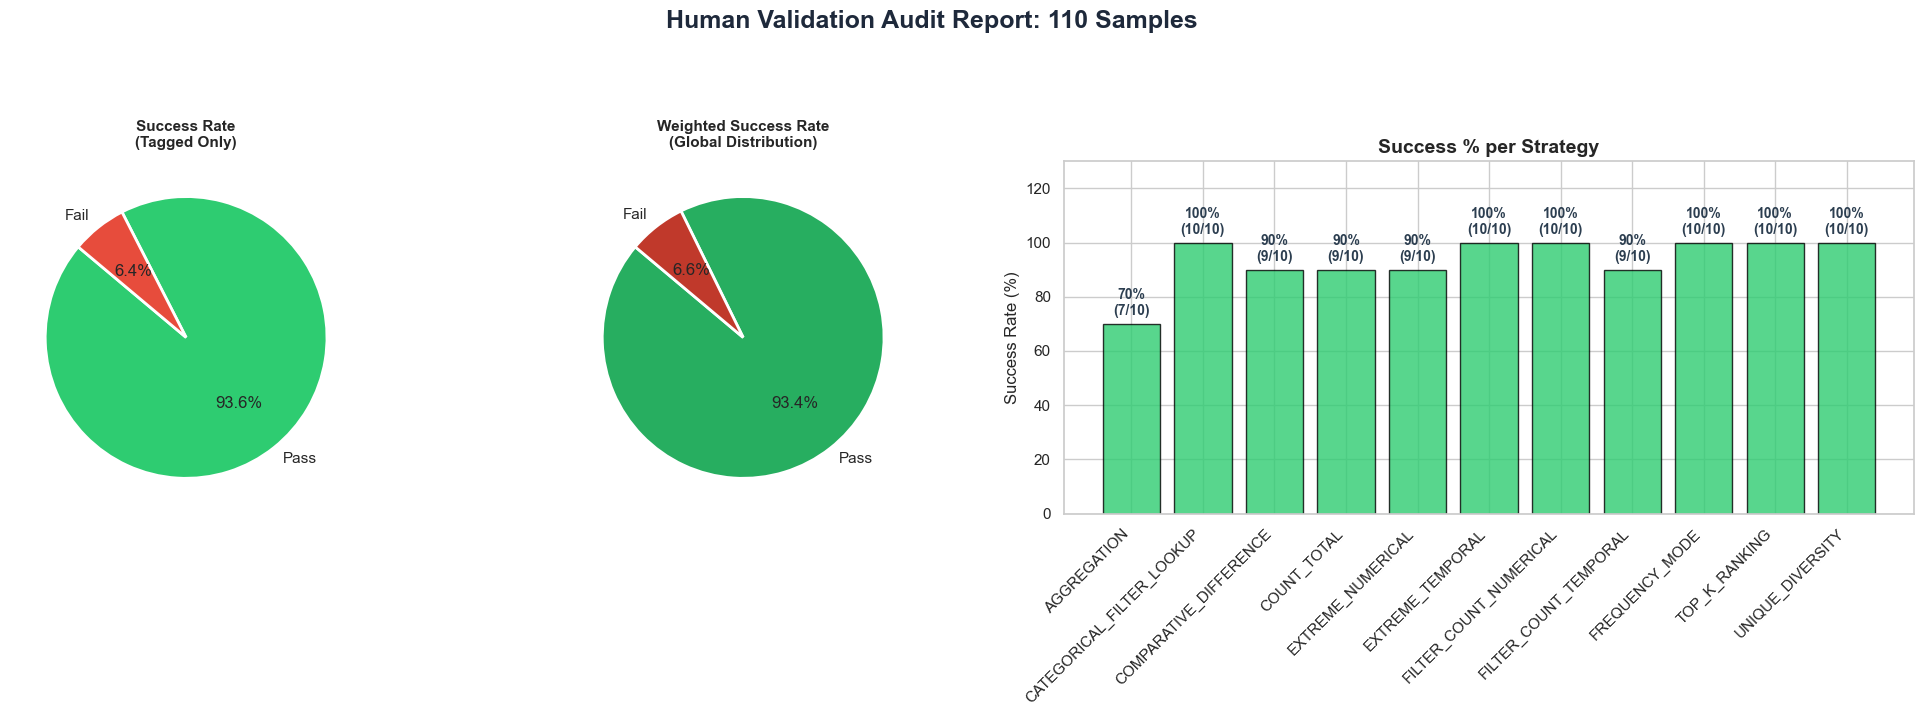

In [108]:
tagger.plot_results()

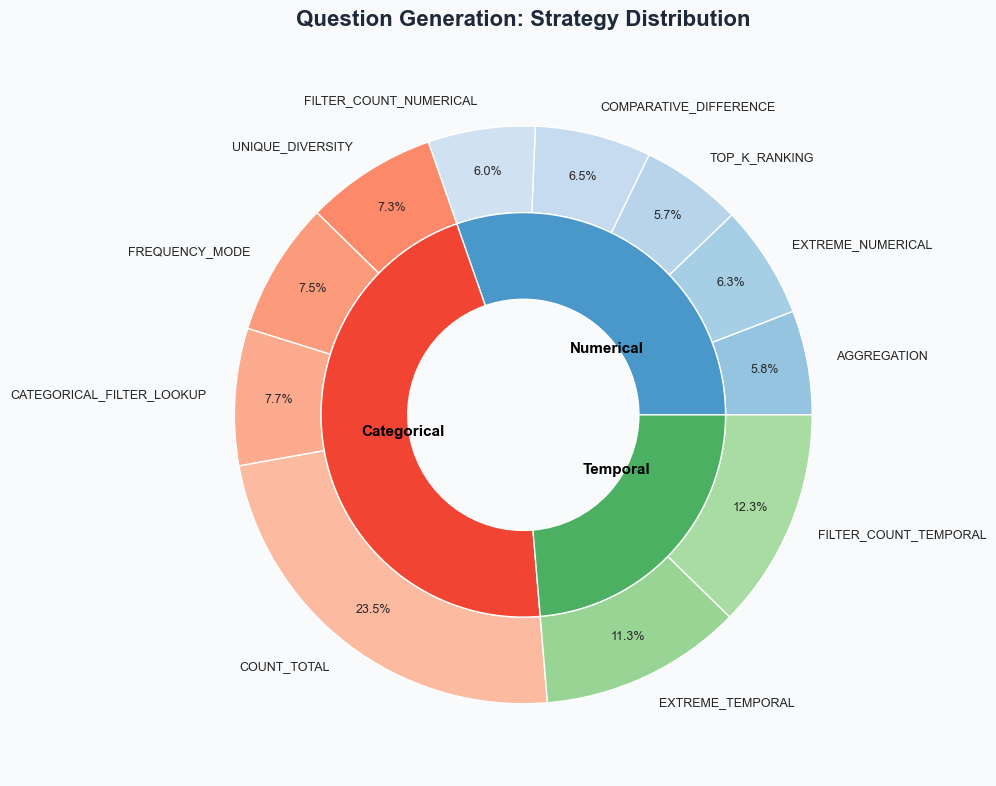

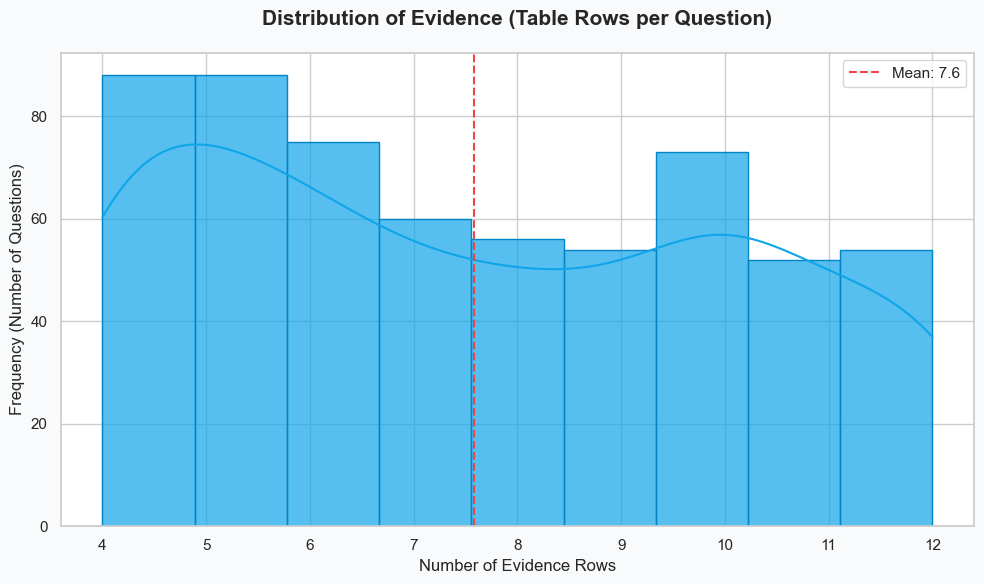

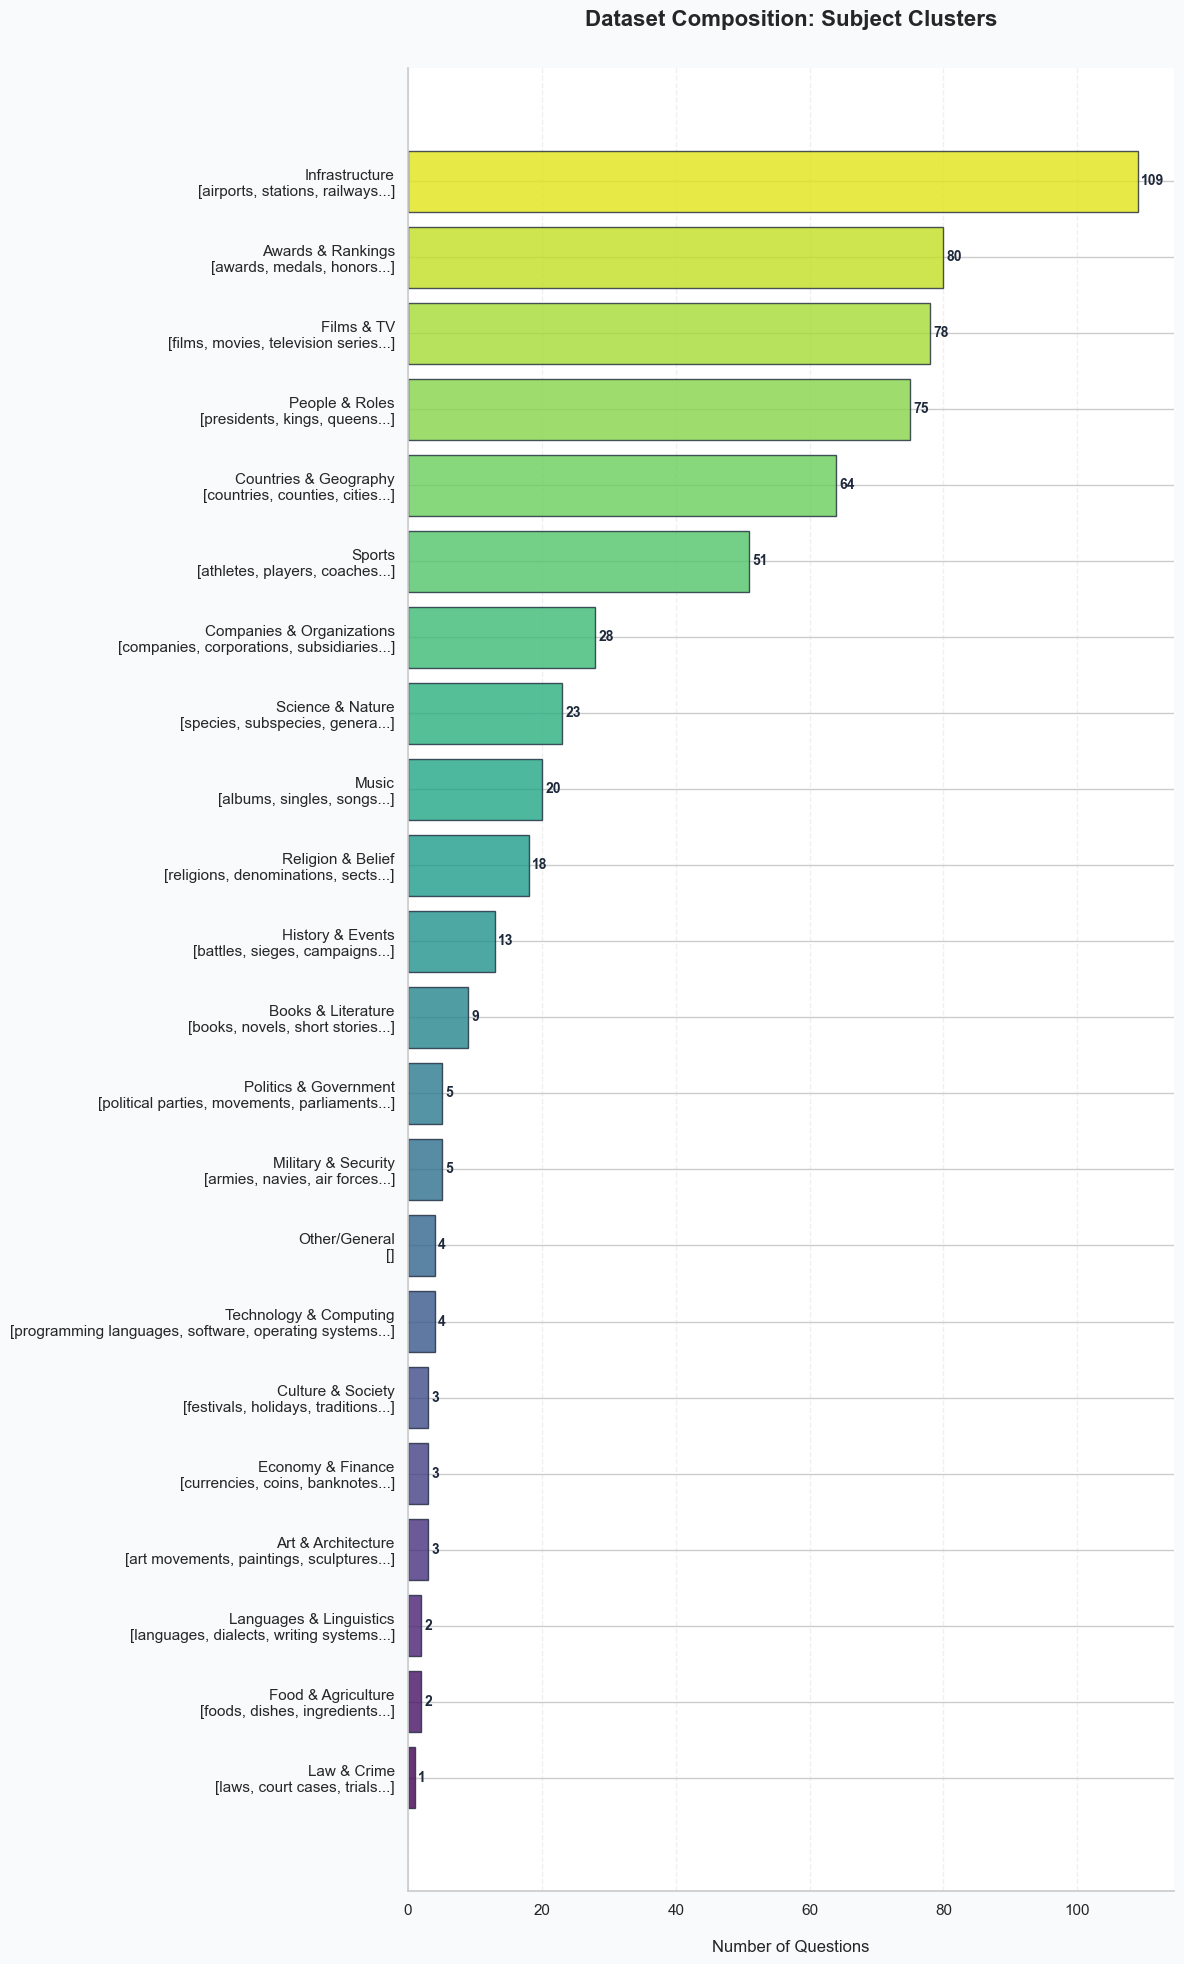

In [66]:
from knowledge_maze.create_dataset.create_questions.visualization import plot_strategy_sunburst, plot_evidence_distribution, plot_subject_distribution
plot_strategy_sunburst(question_data)
plot_evidence_distribution(question_data)
plot_subject_distribution(question_data)

### Show Some Data Samples:

In [60]:
from knowledge_maze.create_dataset.create_questions.visualization import visualize_samples
visualize_samples(question_data)

# API Stuff:

In [199]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import GroupValidatorTest

group_val = GroupValidatorTest(random.sample(group_constructor.valid_tables, 4))
await group_val.validate()

rev = Counter([sample['verdict'] for sample in group_val.output_data])
print(f"{100 * rev[True] / sum(rev.values()):.1f}%")
rev

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/4 [00:00<?, ?it/s]

ChatCompletion(id='gen-1773190353-q2hzZ6AWwTuuDHm1Vo26', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='True', refusal=None, role='assistant', audio=None, function_call=None, tool_calls=None, reasoning='**Evaluating Group Cohesion**\n\nI\'m currently focused on the coherence of the group "Wind power stations in Iran." Initial assessments suggest a common theme, but I need to ascertain if the group is specific enough to be meaningful. I\'m investigating if the shared location and function constitute a naturally occurring group, or if further refinement is necessary. The group size seems manageable for now.\n\n\n**Defining Group Membership**\n\nI\'ve confirmed each entity\'s presence within the specified geographic and functional criteria. The group\'s coherence is demonstrable, with all members adhering to the definition of "wind power stations in Iran." The entity column\'s members are valid, and the group definition provides a clea

Counter({None: 4})

In [184]:
for s in [sample for sample in group_val.output_data if not sample['verdict']]:
    print(s['Group name'])
    print(s['Entity column'])
    print(s['Wiki url'])
    print("-"*100)

Members of Task Force ✱/Suicide Squad Dark
Character
https://en.wikipedia.org/wiki/List_of_Suicide_Squad_members#Task_Force_%E2%9C%B1/Suicide_Squad_Dark
----------------------------------------------------------------------------------------------------
Top 5 mainland Chinese albums by annual sales percentage on the Billboard China V Chart in 2016
Album
https://en.wikipedia.org/wiki/List_of_Billboard_China_V_Chart_top_10_albums_of_2016#Mainland_%28Domestic%29_albums
----------------------------------------------------------------------------------------------------
Taiwanese films released in 2001
Title
https://en.wikipedia.org/wiki/List_of_Taiwanese_films_of_the_2000s#2001
----------------------------------------------------------------------------------------------------


In [187]:
from knowledge_maze.create_dataset.create_questions.grouping_entities import GroupValidator

group_val = GroupValidator([sample for sample in group_val.output_data if sample['verdict']])
await group_val.validate()

rev = Counter([sample['verdict'] for sample in group_val.output_data])
print(f"{100 * rev['ACCEPT'] / sum(rev.values()):.1f}%")
rev

Usage cost: 0.0000$ (Estimated: 0.00$):   0%|          | 0/17 [00:00<?, ?it/s]

Input tokens: 642
Output tokens: 188
Input tokens: 577
Output tokens: 271
Input tokens: 578
Output tokens: 207
Input tokens: 519
Output tokens: 255
Input tokens: 629
Output tokens: 236
Input tokens: 622
Output tokens: 251
Input tokens: 533
Output tokens: 369
Input tokens: 624
Output tokens: 406
Input tokens: 616
Output tokens: 430
Input tokens: 606
Output tokens: 548
Input tokens: 630
Output tokens: 182
Input tokens: 596
Output tokens: 217
Input tokens: 607
Output tokens: 155
Input tokens: 571
Output tokens: 238
Input tokens: 544
Output tokens: 219
Input tokens: 580
Output tokens: 892
Input tokens: 581
Output tokens: 181
94.1%


Counter({'ACCEPT': 16, 'CLOSED_SET': 1})